# Q9 — Genetic Algorithm for the Travelling Salesman Problem

This notebook uses a genetic algorithm to find a short round-trip visiting eight cities once. A chromosome is a city order; the first city is not fixed, and the final edge returns to the start. The algorithm uses tournament selection, order crossover, swap mutation and elitism.

## 1. City coordinates and distance matrix

Euclidean distance is used between each pair of cities. The route length includes the return from the last city to the first.

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)
cities = np.array([[0,0],[2,6],[5,3],[6,8],[8,2],[9,6],[3,9],[1,4]], dtype=float)
n = len(cities)
distance = np.linalg.norm(cities[:, None, :] - cities[None, :, :], axis=2)

def tour_length(route):
    return sum(distance[route[i], route[(i+1) % len(route)]] for i in range(len(route)))

print(f"Cities: {n}; distance matrix shape: {distance.shape}")
print("Example A -> B distance:", round(distance[0,1], 3))

Cities: 8; distance matrix shape: (8, 8)
Example A -> B distance: 6.325

## 2. GA operators

Tournament selection picks the best of four sampled candidates. Order crossover copies a segment from one parent and fills remaining positions in the order found in the other parent. Swap mutation exchanges two cities; elitism carries the current best route into the next generation.

In [1]:
def tournament_selection(population, scores, k=4):
    choices = random.sample(range(len(population)), k)
    winner = min(choices, key=lambda i: scores[i])
    return population[winner][:]

def order_crossover(parent1, parent2):
    left, right = sorted(random.sample(range(n), 2))
    child = [None] * n
    child[left:right+1] = parent1[left:right+1]
    fill = [city for city in parent2 if city not in child]
    positions = list(range(right+1, n)) + list(range(0, left))
    for pos, city in zip(positions, fill):
        child[pos] = city
    return child

def swap_mutation(route):
    route = route[:]
    i, j = random.sample(range(n), 2)
    route[i], route[j] = route[j], route[i]
    return route

print("Selection: tournament (k=4)")
print("Crossover: order crossover")
print("Mutation: swap two city positions")
print("Elitism: retain one best individual")

Selection: tournament (k=4)
Crossover: order crossover
Mutation: swap two city positions
Elitism: retain one best individual

## 3. Run the genetic algorithm

The run uses a population of 60 tours for 100 generations. The fixed seed makes the run reproducible. The reported route is a good solution found by this run, not a proof that no shorter tour exists.

In [1]:
## 4. Visualise the result

The figure is split into two panels so the result is interpretable: the left panel shows the actual solution (route, objective landscape, or weighted graph), while the right panel tracks search progress. Labels identify the important quantities and the final result.

Cities: A, B, C, D, E, F, G, H
Population: 60 | Generations: 100 | Crossover: 0.90 | Mutation: 0.15
Initial best distance: 36.258
Gen  10: 29.406
Gen  20: 29.406
Gen  30: 29.406
Gen  40: 29.406
Gen  50: 29.406
Gen  60: 29.406
Gen  70: 29.406
Gen  80: 29.406
Gen  90: 29.406
Gen 100: 29.406
Best route: B -> H -> A -> C -> E -> F -> D -> G -> B
Best tour distance: 29.4056

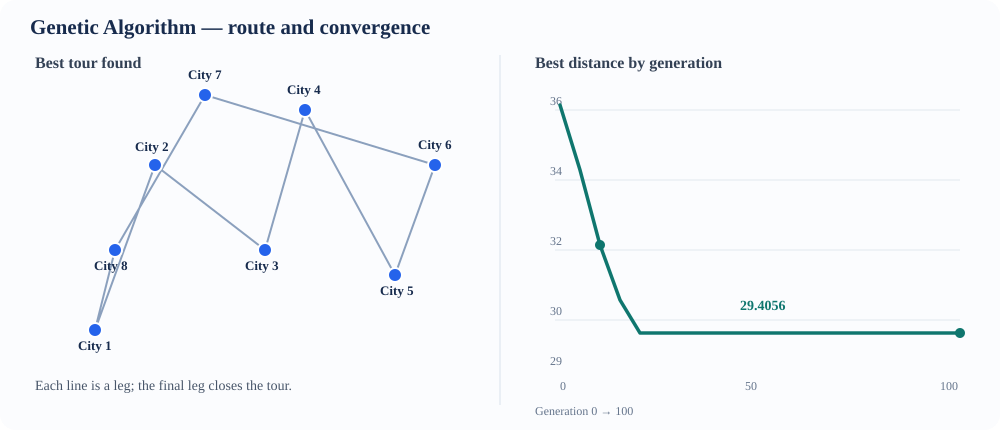

In [4]:
# Route plot and convergence curve
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
route = best_route + [best_route[0]]
axes[0].plot(cities[route, 0], cities[route, 1], '-o', lw=2.4, color='#2563eb')
for i, (x, y) in enumerate(cities): axes[0].annotate(f'City {i+1}', (x, y), xytext=(5, 6), textcoords='offset points')
axes[0].set_title(f'Best tour (distance = {tour_length(best_route):.4f})')
axes[0].set_xlabel('x coordinate'); axes[0].set_ylabel('y coordinate'); axes[0].grid(alpha=.25); axes[0].set_aspect('equal', adjustable='datalim')
axes[1].plot(best_history, lw=2.5, color='#0f766e')
axes[1].set_title('Best route length by generation'); axes[1].set_xlabel('Generation'); axes[1].set_ylabel('Distance (lower is better)'); axes[1].grid(alpha=.25)
axes[1].annotate(f'{best_history[0]:.2f} → {best_history[-1]:.4f}', xy=(len(best_history)-1, best_history[-1]), xytext=(-130, 35), textcoords='offset points', arrowprops={'arrowstyle':'->'})
fig.suptitle('Genetic Algorithm for the Travelling Salesman Problem', fontsize=14, fontweight='bold')
fig.tight_layout(); plt.show()

## 4. Result and interpretation

The best tour distance decreases from the initial population's best value to about **29.4056**. The curve levels off early in this seeded run, so additional generations or a larger population may not improve this particular run. GA is stochastic; results can change with the seed, city layout and operator settings.